# 10 — Attention : quelles coupes sont ignorées

Les 24 coupes NPZ sont un **linspace dans la bande 20–80 %**. Chaque tête fait un softmax sur 72 positions (3 plans × 24).

**v11** : 72 vecteurs GAP partagés ; les 12 têtes ne diffèrent que par le score.

**v14** : le **score de coupe** est encore calculé sur ces 72 GAP (`attn_score`). Le **pooling** utilise **72 × 12** vecteurs CAM (un par maladie). `interpret()` fournit les deux. Une cellule plus bas compare au contrefactuel « scorer la coupe sur le token CAM » (piste v15).

Défaut : **subset v14** gold (`subset_v14_crop130_frac025`). `SPLIT = "val"` charge les 653 études déjà calculées. Pour le v11 full (LB 0,914) : décommenter l’autre `CONFIG`.

```text
python -X utf8 -m src.infer.inspect_attention --config configs/kneenet_v14_crop130_subset.yaml --split gold --workers 0
python -X utf8 -m src.infer.inspect_attention --config configs/kneenet_v14_crop130_subset.yaml --split val --workers 0
```


In [12]:
from __future__ import annotations

import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.infer.inspect_attention import load_config, run

CONFIG = ROOT / "configs" / "kneenet_v14_crop130_subset.yaml"
# CONFIG = ROOT / "configs" / "kneenet_v11_crop130.yaml"  # full v11, LB 0.914
FORCE = False
SPLIT = "gold"  # "val" (653) | "gold" (58)
MAX_STUDIES = None

cfg = load_config(str(CONFIG))
OUT = ROOT / "checkpoints" / cfg["run_name"] / "attention_inspect"
if SPLIT == "gold":
    OUT = ROOT / "checkpoints" / cfg["run_name"] / "attention_inspect_gold"
CKPT = ROOT / "checkpoints" / cfg["run_name"] / "best.pt"
if not CKPT.exists():
    CKPT = ROOT / "checkpoints" / cfg["run_name"] / "last.pt"
print("config", CONFIG.name)
print("ckpt  ", CKPT, "exists", CKPT.exists())
print("out   ", OUT)

config kneenet_v14_crop130_subset.yaml
ckpt   c:\Users\sulta\Documents\RSNA-comp\checkpoints\subset_v14_crop130_frac025\best.pt exists True
out    c:\Users\sulta\Documents\RSNA-comp\checkpoints\subset_v14_crop130_frac025\attention_inspect_gold


In [13]:
import torch

summary_path = OUT / "summary.json"
if summary_path.exists() and not FORCE:
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    print("chargé", summary_path)
else:
    device = "cuda" if torch.cuda.is_available() else "cpu"
    summary = run(
        cfg, CKPT, SPLIT, OUT, device,
        batch_size=int(cfg.get("batch_size") or 4),
        num_workers=0,
        max_studies=MAX_STUDIES,
        n_examples=4,
    )

print(
    f"{summary['model']}  epoch {summary['epoch']}  "
    f"val AUC {summary['val_macro_auc']}  "
    f"{summary['split']} n={summary['n_studies']}"
)


chargé c:\Users\sulta\Documents\RSNA-comp\checkpoints\subset_v14_crop130_frac025\attention_inspect_gold\summary.json
kneenet_v14  epoch 10  val AUC 0.8292234011134892  gold n=58


In [14]:
tbl = pd.read_csv(OUT / "slice_attention.csv")
sug = summary["suggested"]
dead = summary["dead_idx"]
tbl["flag"] = ""
tbl.loc[tbl.slice.isin(sug["drop_idx"]), "flag"] = "bord 90%"
tbl.loc[tbl.slice.isin(dead), "flag"] = "morte"
display(
    tbl.style.format({
        "depth_pct": "{:.0f}%",
        "mass": "{:.2%}",
        "pct_top5_any": "{:.1%}",
        "mass_sag": "{:.4f}",
        "mass_cor": "{:.4f}",
        "mass_axi": "{:.4f}",
    })
)
print(
    f"90 % de la masse : coupes {sug['keep_lo']}–{sug['keep_hi']} "
    f"({sug['n_keep']}/24) → bande "
    f"{100*sug['band_lo']:.0f}–{100*sug['band_hi']:.0f} % "
    f"(masse {100*sug['kept_mass']:.1f} %)"
)
print("coupes mortes :", dead if dead else "(aucune au sens strict)")
print(
    f"sans reconvertir : x[:, :, {sug['keep_lo']}:{sug['keep_hi']+1}]  "
    f"(D={sug['n_keep']})"
)
print(
    f"reconvertir : BAND=({sug['band_lo']:.2f}, {sug['band_hi']:.2f}) "
    f"et garder 24 coupes"
)

,slice,depth_pct,mass,pct_top5_any,mass_sag,mass_cor,mass_axi,flag
0,0,20%,3.88%,47.1%,0.0156,0.0114,0.0118,bord 90%
1,1,23%,4.09%,48.9%,0.0170,0.0118,0.0121,
2,2,25%,4.04%,48.9%,0.0169,0.0116,0.0119,
3,3,28%,4.21%,46.0%,0.0177,0.0121,0.0123,
4,4,30%,4.19%,48.9%,0.0169,0.0123,0.0128,
5,5,33%,4.16%,44.8%,0.0162,0.0128,0.0126,
6,6,36%,4.18%,50.0%,0.0160,0.0130,0.0128,
7,7,38%,4.15%,47.1%,0.0151,0.0133,0.0131,
8,8,41%,4.14%,46.6%,0.0146,0.0137,0.0130,
9,9,44%,4.08%,50.6%,0.0139,0.0140,0.0129,


90 % de la masse : coupes 1–22 (22/24) → bande 23–77 % (masse 92.4 %)
coupes mortes : (aucune au sens strict)
sans reconvertir : x[:, :, 1:23]  (D=22)
reconvertir : BAND=(0.23, 0.77) et garder 24 coupes


attn_profile.png


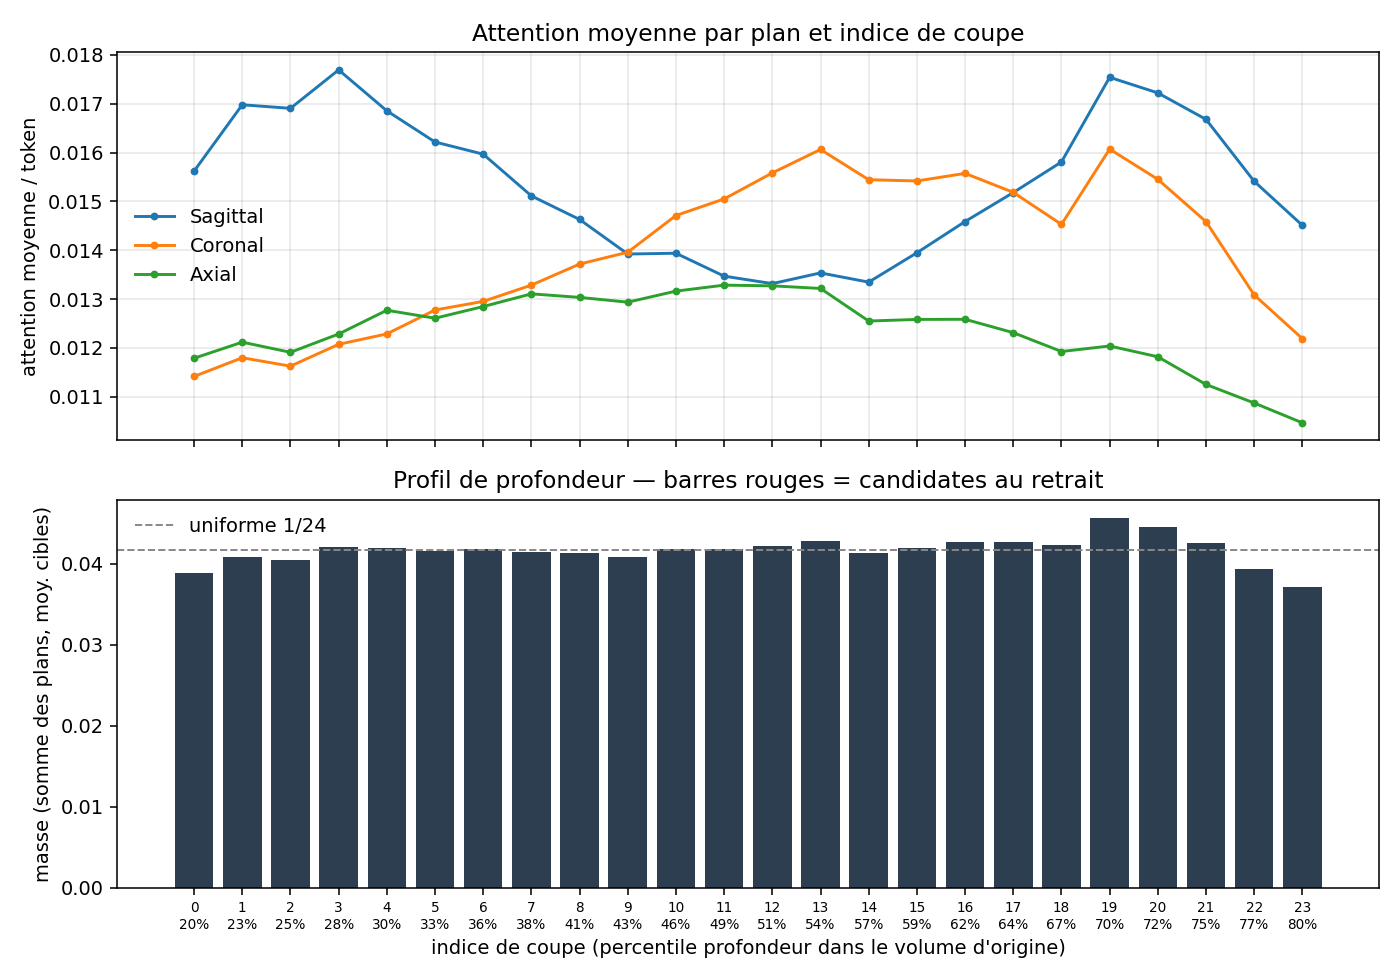

attn_heatmap_planes.png


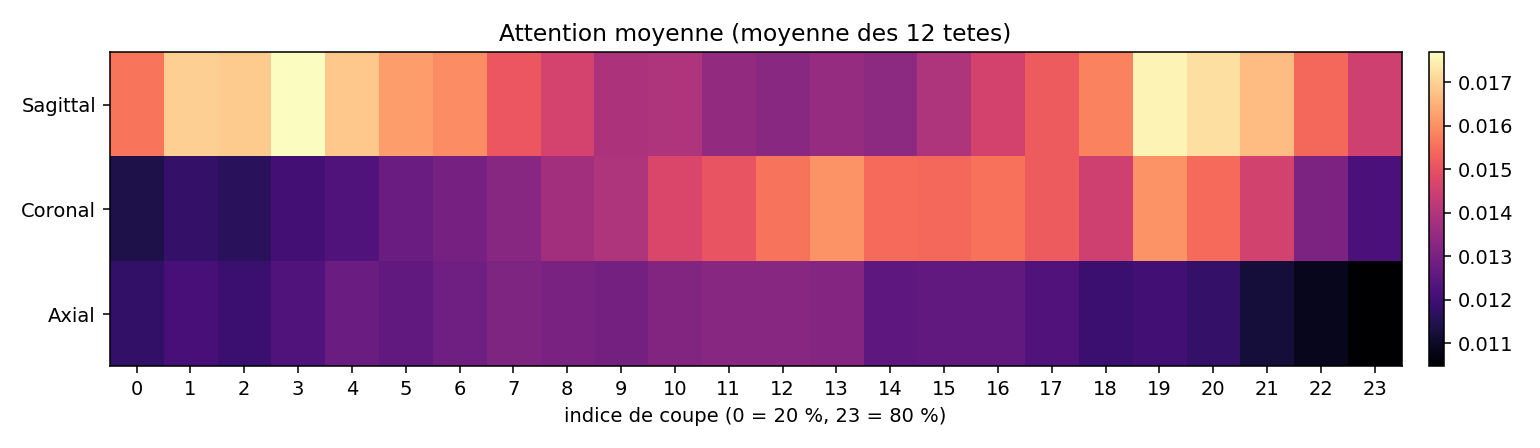

attn_heatmap_targets.png


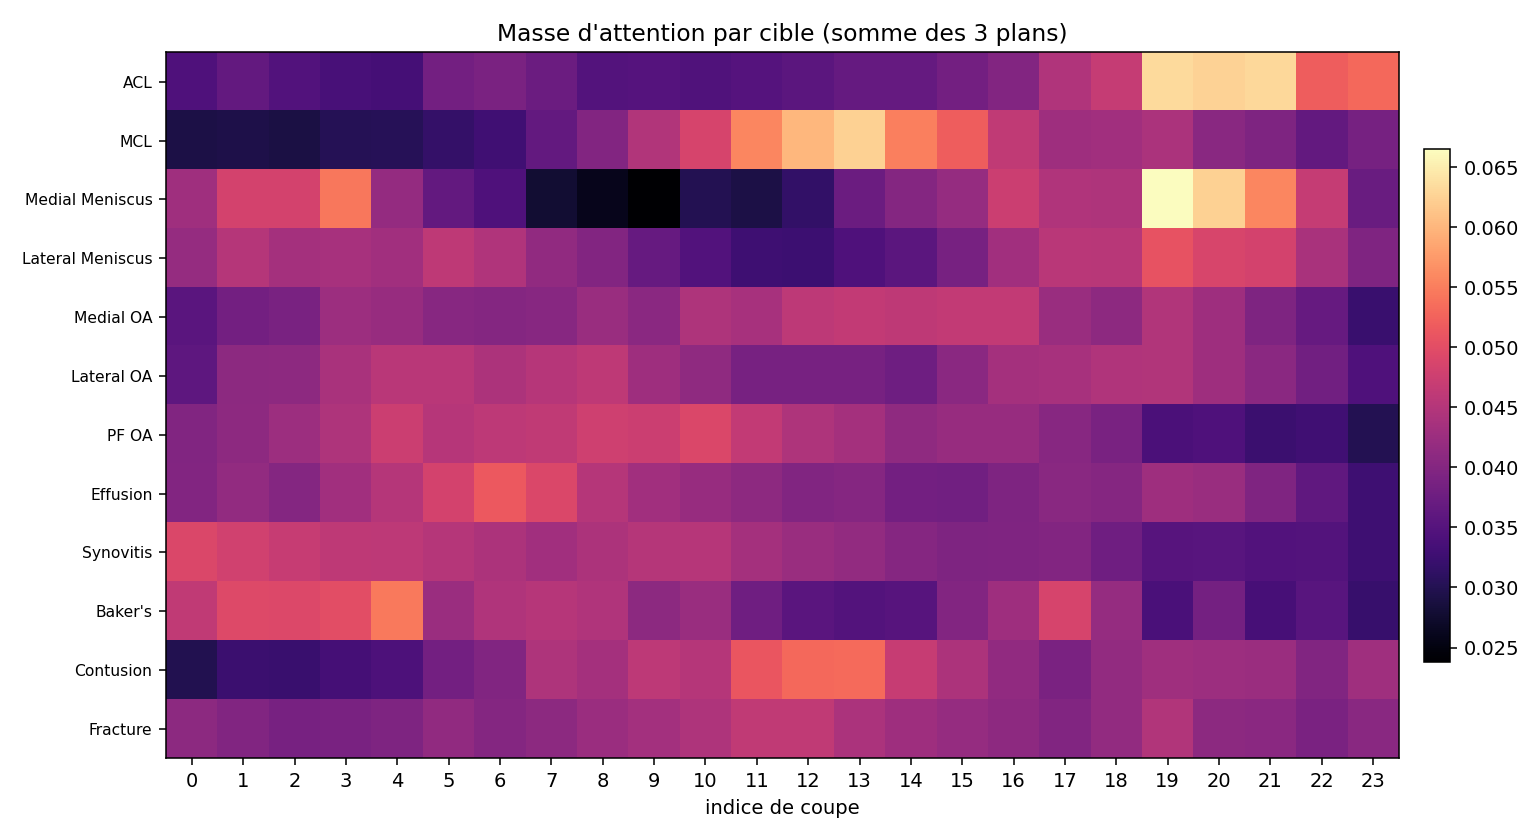

In [15]:
for name in ("attn_profile.png", "attn_heatmap_planes.png", "attn_heatmap_targets.png"):
    p = OUT / name
    print(p.name)
    display(Image(filename=str(p)))

12 mosaics
ex0_ACL.png


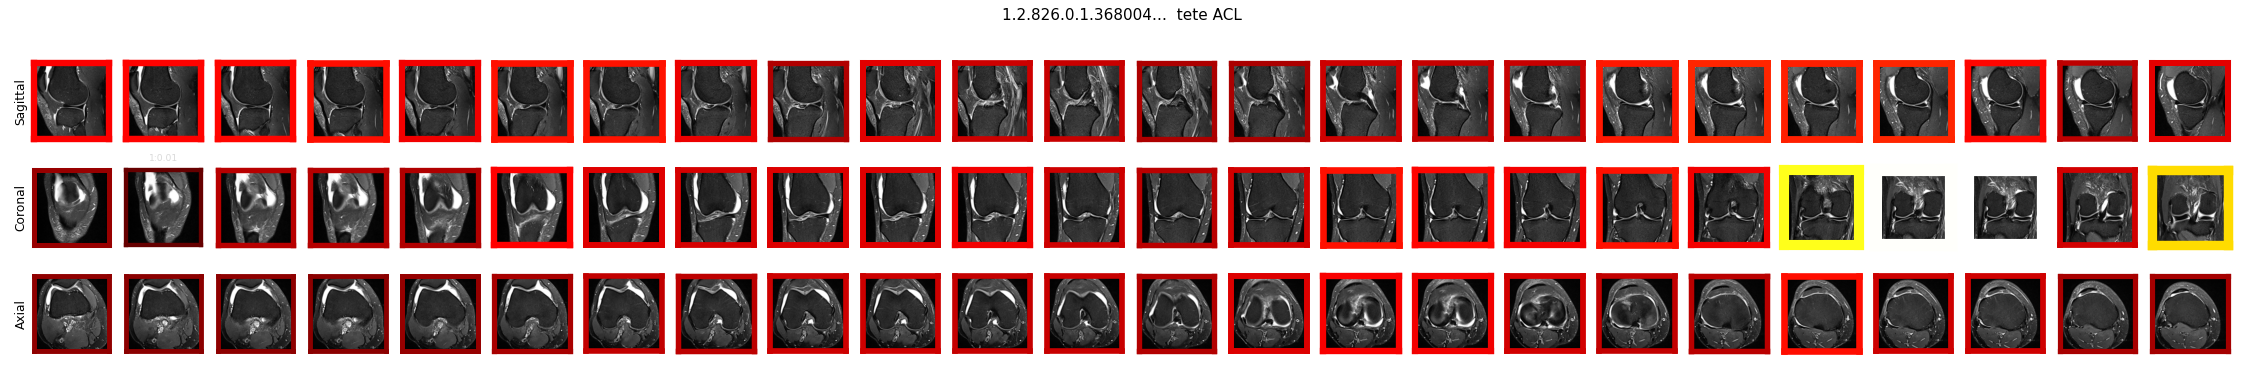

ex0_Bakers.png


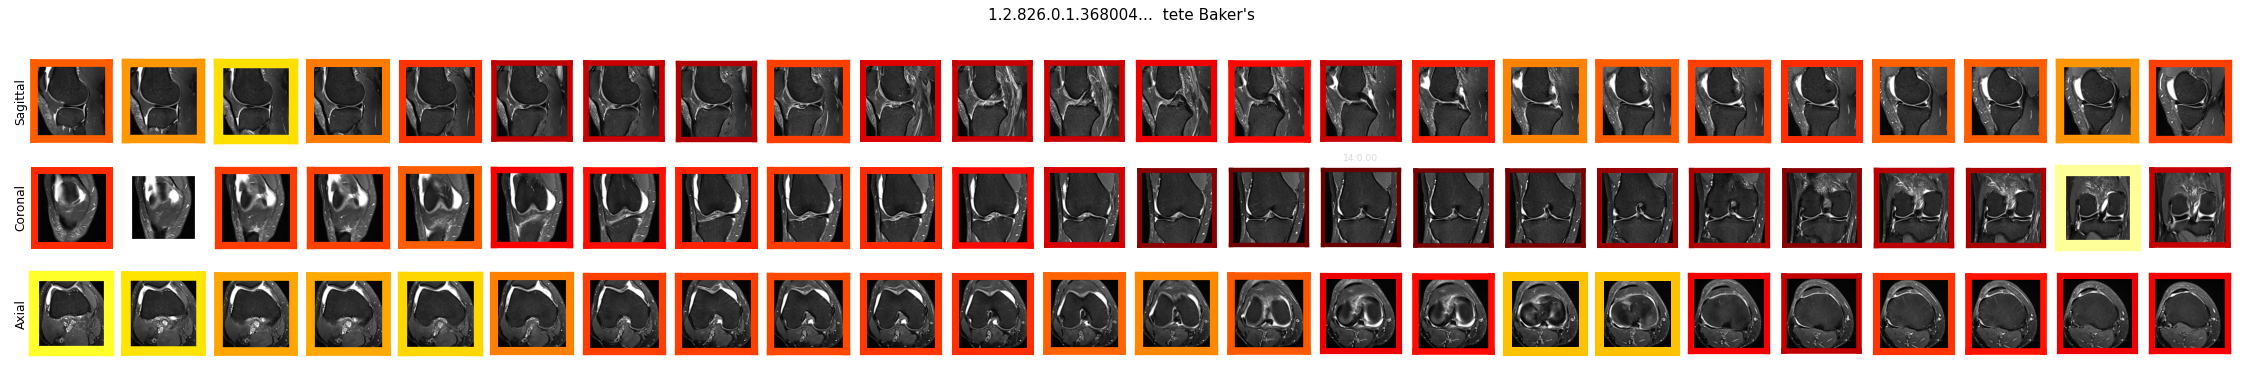

ex0_Effusion.png


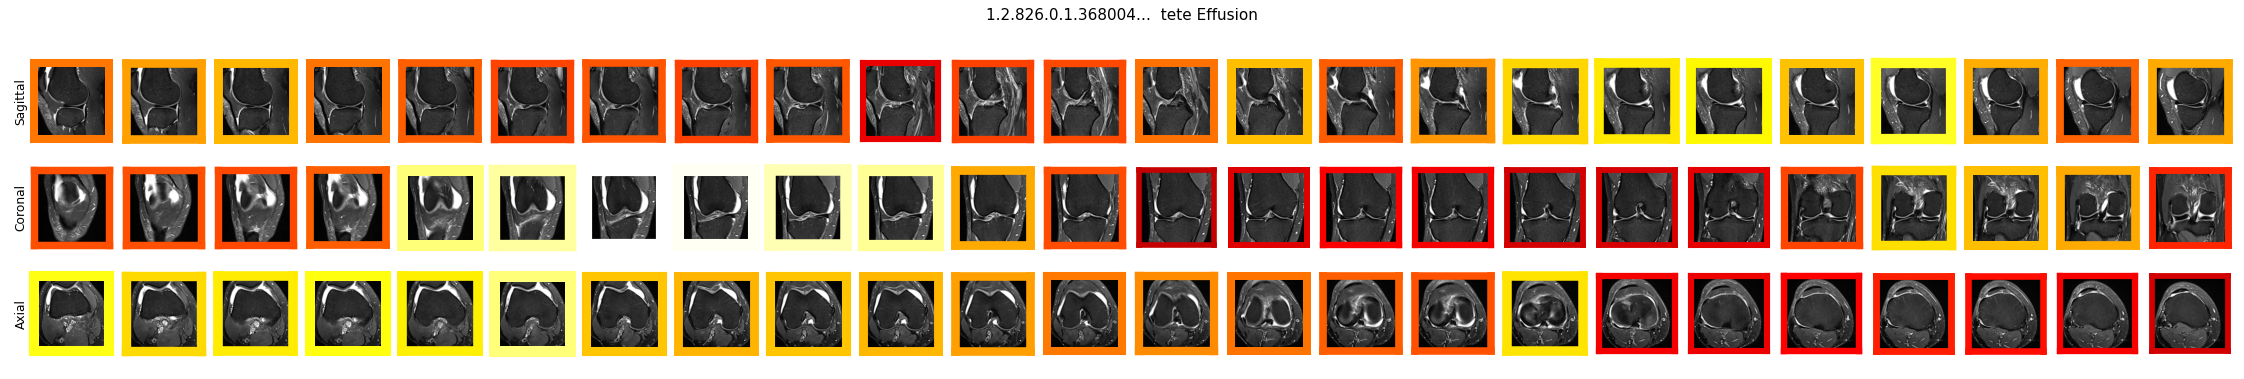

ex1_ACL.png


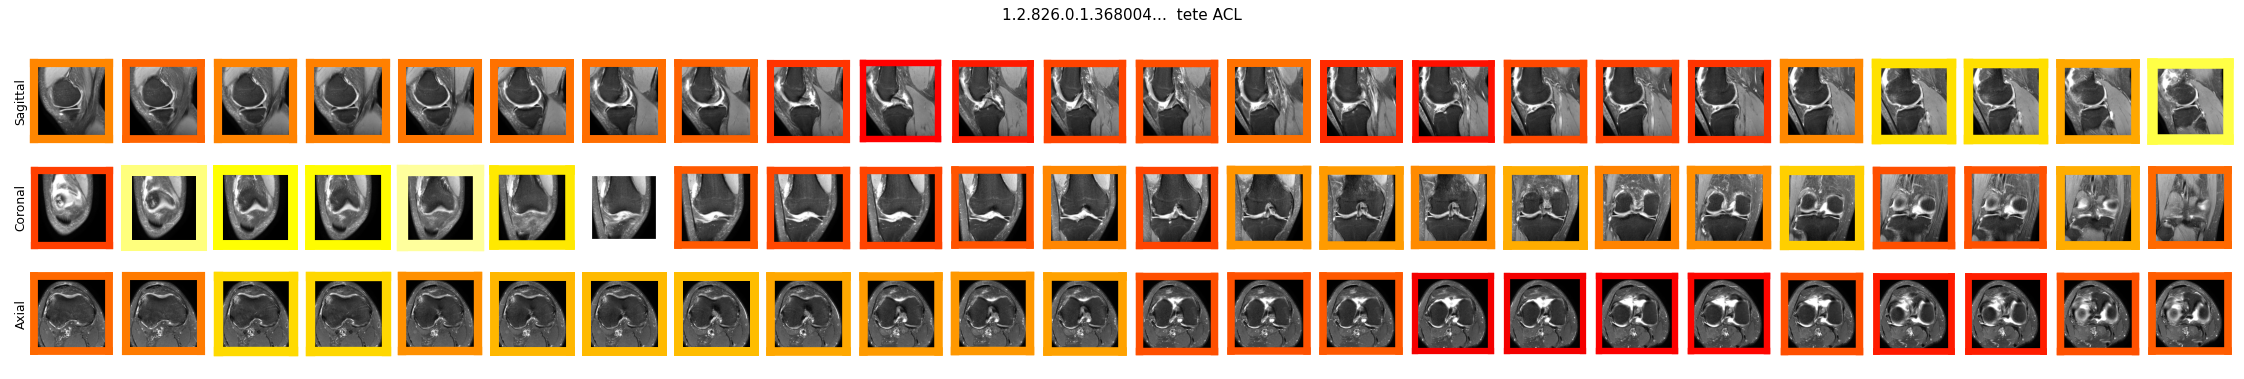

ex1_Bakers.png


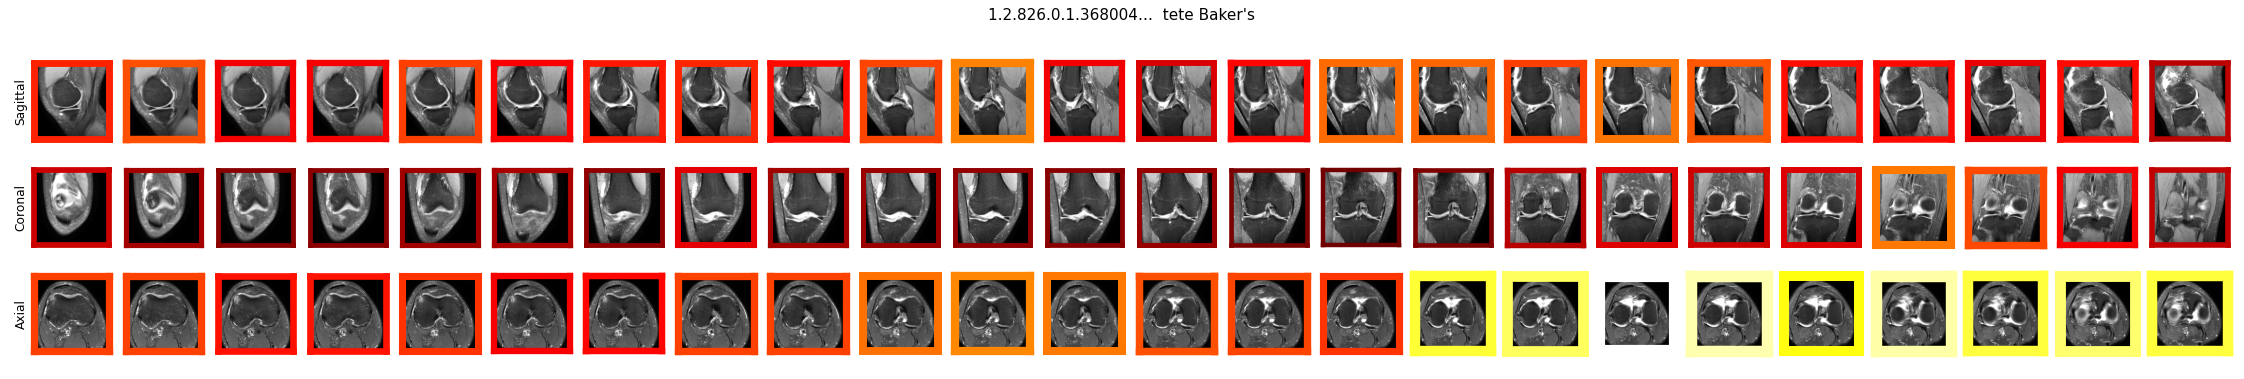

ex1_Effusion.png


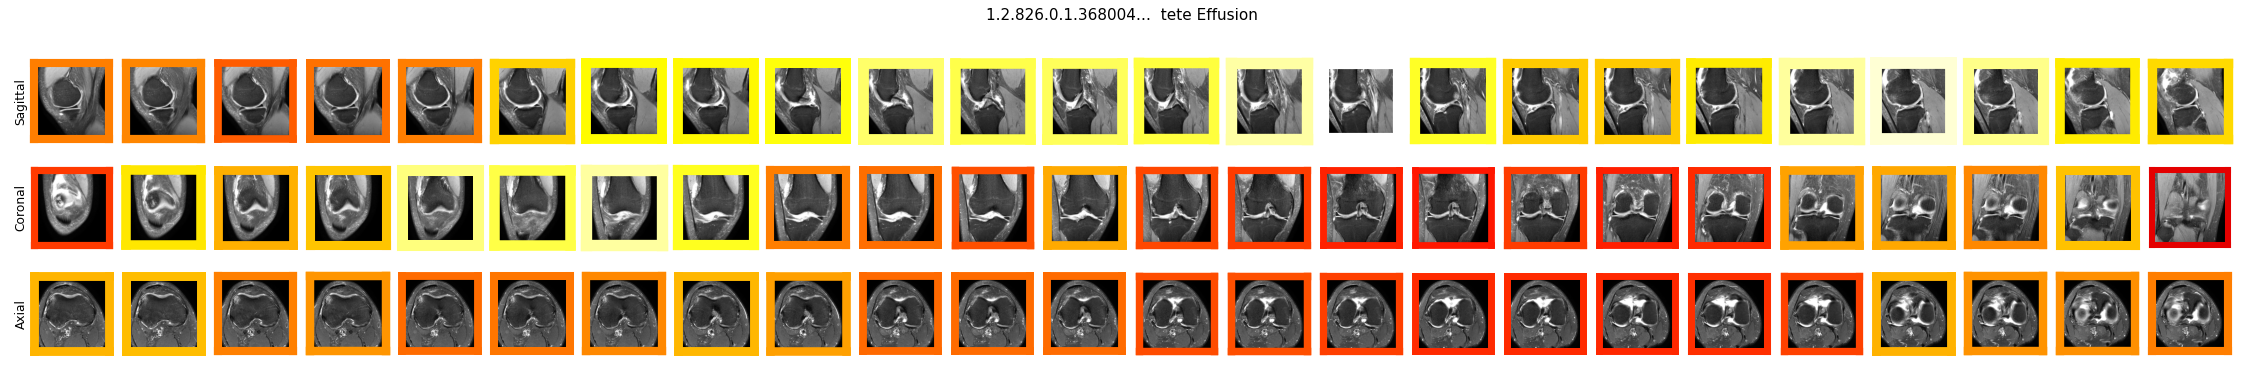

In [16]:
ex_dir = OUT / "examples"
files = sorted(ex_dir.glob("*.png")) if ex_dir.exists() else []
print(len(files), "mosaics")
for p in files[:6]:
    print(p.name)
    display(Image(filename=str(p)))

## v14 — 72 GAP vs 72×12 tokens CAM

Le **forward v14** score encore les 72 GAP, puis pondère les tokens CAM. Les 12× plus de vecteurs changent donc le **contenu poolé**, pas le **choix de coupe**.

La cellule suivante calcule un **contrefactuel** : passer `attn_score` (entraîné sur GAP) sur le token CAM de chaque tête, puis softmax coupe. Ce n’est **pas** le modèle entraîné — aperçu de ce que ferait un v15 qui scorerait les tokens CAM.


c:\Users\sulta\Documents\RSNA-comp\checkpoints\subset_v14_crop130_frac025\attention_inspect_gold\gap_vs_cam_slice.csv
corr mediane 0.909  pics differents 6/12


,target,corr,peak_gap,peak_cam,plane_gap,plane_cam
0,ACL,0.903,19,21,Coronal,Coronal
1,MCL,0.905,13,13,Coronal,Coronal
2,Medial Meniscus,0.912,19,19,Sagittal,Coronal
3,Lateral Meniscus,0.928,19,18,Sagittal,Sagittal
4,Medial OA,0.963,13,13,Sagittal,Sagittal
5,Lateral OA,0.918,8,5,Sagittal,Sagittal
6,PF OA,0.981,10,10,Axial,Axial
7,Effusion,0.932,6,6,Sagittal,Sagittal
8,Synovitis,0.880,0,0,Sagittal,Sagittal
9,Baker's,0.608,4,16,Axial,Axial


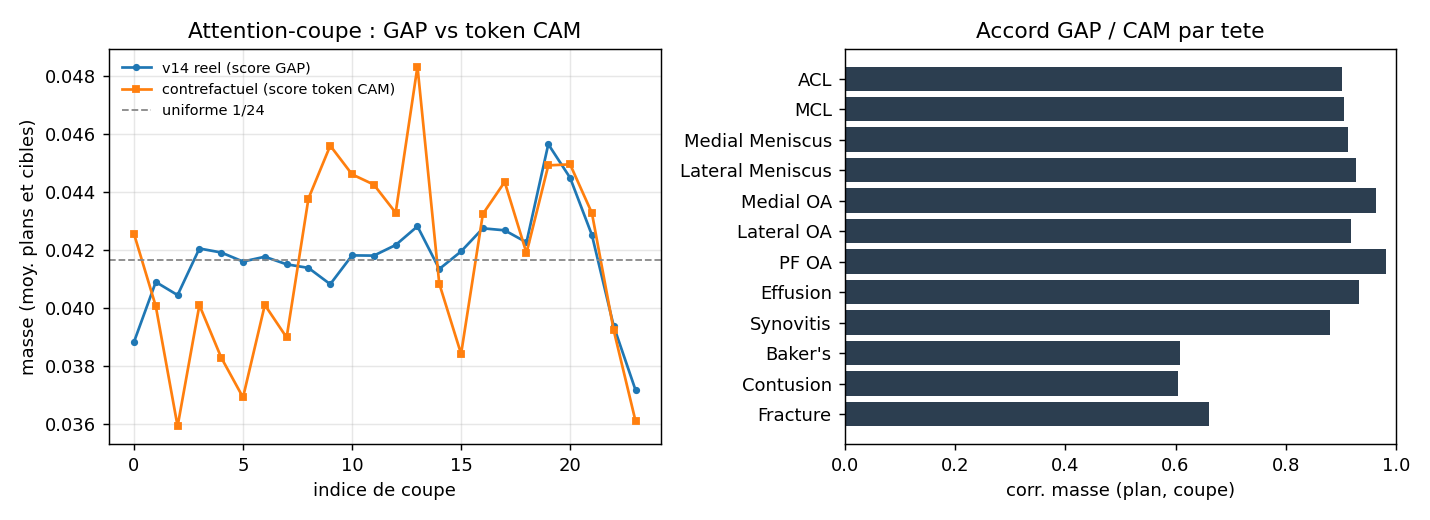

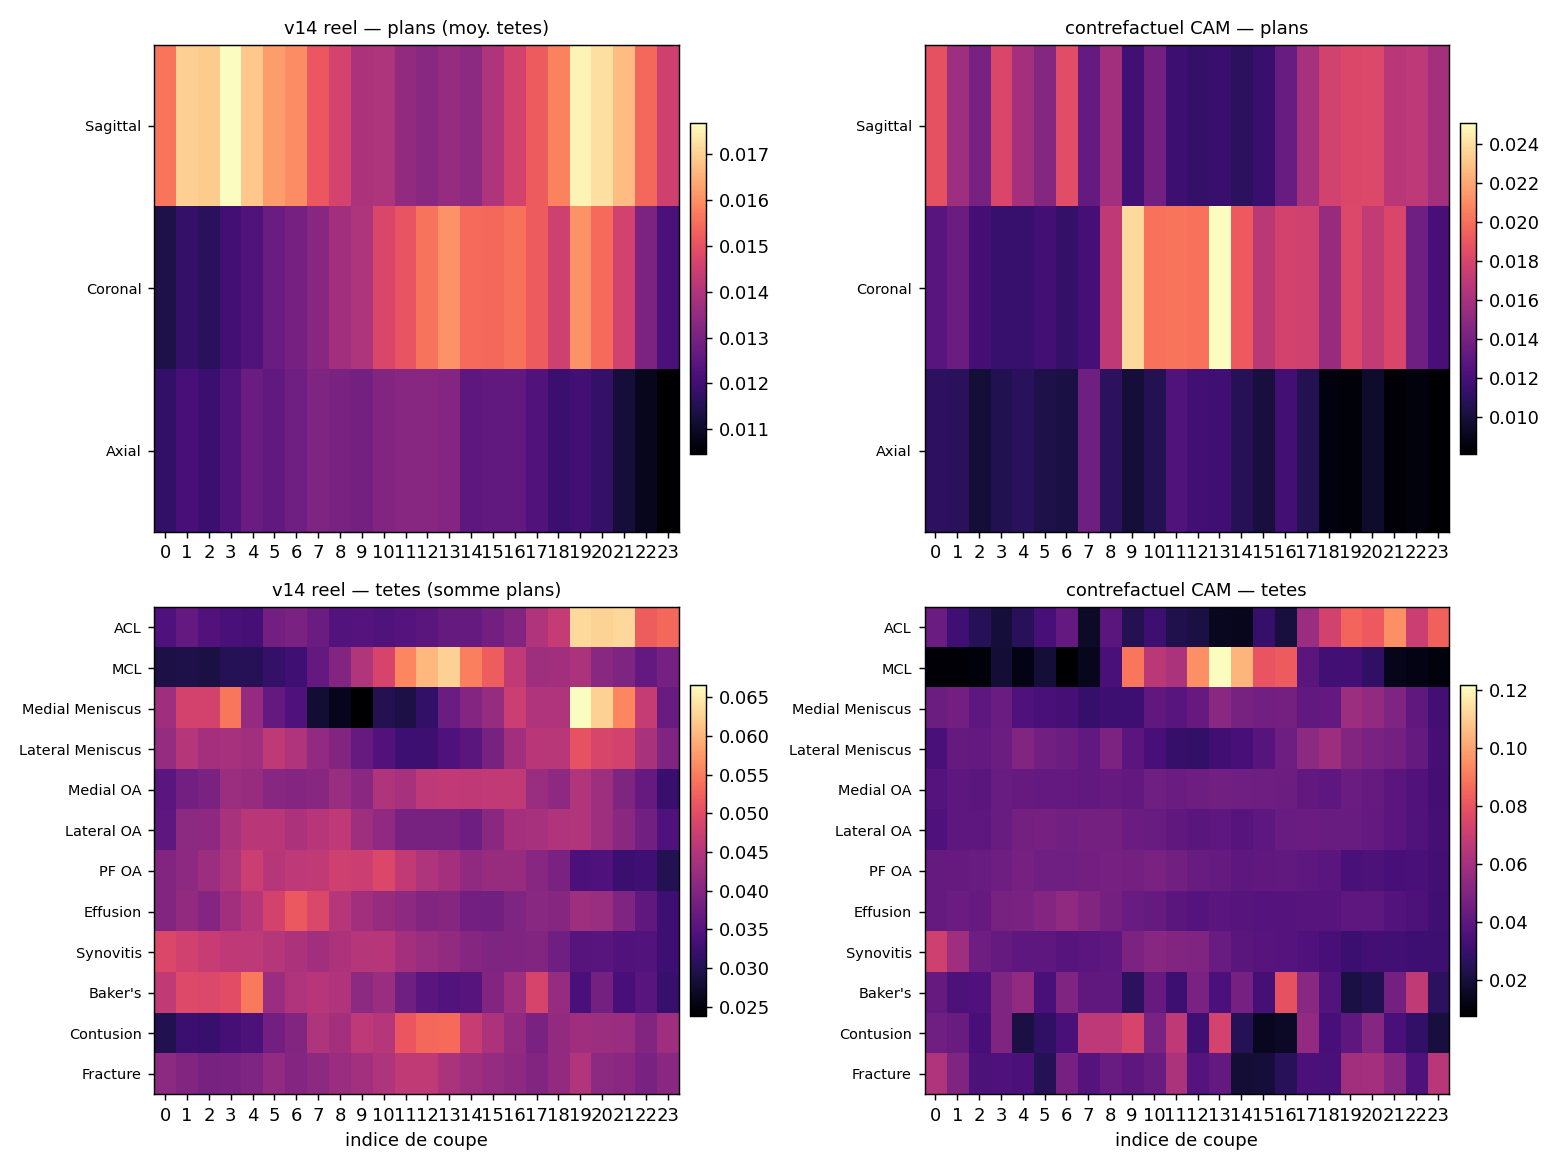

In [17]:
CMP_CSV = OUT / "gap_vs_cam_slice.csv"
if cfg.get("model") != "kneenet_v14":
    print("sauter : CONFIG n'est pas v14 (", cfg.get("model"), ")")
elif not CMP_CSV.exists():
    print("pas encore de gap_vs_cam_slice.csv — relancer la cellule 2 avec FORCE=True")
else:
    cmp_tbl = pd.read_csv(CMP_CSV)
    print(CMP_CSV)
    print(
        f"corr mediane {cmp_tbl['corr'].median():.3f}  "
        f"pics differents {(cmp_tbl.peak_gap != cmp_tbl.peak_cam).sum()}/{len(cmp_tbl)}"
    )
    display(cmp_tbl.round(3))
    for name in ("gap_vs_cam_slice.png", "gap_vs_cam_heatmaps.png"):
        p = OUT / name
        if p.exists():
            display(Image(filename=str(p)))


## Lecture (v14 subset — val 653 et gold 58)

Le softmax coupe v14 est **quasi uniforme** (masse 3,7–4,6 % vs 4,17 % = 1/24). **Aucune coupe morte.** L’auto-trim « drop 0 et 23 » n’enlève que des bords à peine plus pauvres : **ne pas retirer d’indices NPZ ni resserrer BAND**.

Plans (val) : sag 36,5 % / cor 33,1 % / ax 30,4 % — axial plus utilisé qu’en v11 full (~22 %). Pics GAP encore anatomiques : ACL/ménisques ~ coupe 19 (~70 %), MCL/OA médial ~13, épanchement ~6, PF OA ~10 (axial).

**72×12 tokens :** le forward v14 score toujours les GAP. Le contrefactuel « scorer le token CAM » (médiane corr **0,94** val / **0,91** gold) ne bouge presque pas les têtes encore GAP-like (OA, ménisques, épanchement). Il diverge là où le CAM 7×7 est piqué : **contusion** (corr val 0,21), fracture (0,57), Baker (0,78). Scorer les tokens CAM n’est utile que pour ces têtes — et seulement si on **entraîne** `attn_score` dessus (v15), pas en réutilisant les poids GAP.
